# 09b · Model A+B: physics-structured outputs on hierarchical Gaussian processes

*Level: advanced. Guide Sections 12–13. Code: `structured.PhysicsStructured(kind="hier")`; in level 1: `train_lvl1.py --models physics_hier`.*

**Idea.** A+B combines the two previous notebooks:
* **A (08)** gives the *structure*: the noise is measured on the trace, and only the gain, a small correction and λ are learned;
* **B (09)** gives the *learner*: each of those three functions is a hierarchical GP that knows the data come from amplifiers on modules.

$$\log\sigma_e = \tfrac12\log\!\Bigl(\frac{a^2}{N}+b^2\Bigr) - \log\hat g(x; m, j) + \hat r(x; m, j),\qquad \log\hat\lambda(x; m, j),$$

where $m$ is the module and $j$ the amplifier. Each hat is a GP with the kernel of notebook 09:

$$k = \sigma_f^2 M + \mathbb 1[m=m'](c_m^2+\sigma_m^2M) + \mathbb 1[j=j'](c_a^2+\sigma_a^2M) + \sigma_n^2\,\mathbb 1[i=i'] .$$

**Its history.**
* It was the project's first recommended model (2026-10-14): σe to 2–3 % from 15 packets, and a new module learned from 1–2 packets.
* The default then became **A without labels** (`PhysicsStructured()`): giving each amplifier's own traces instead of its identity was as good, and works for any amplifier.

A+B stays as a **labelled reference**. Level 1 runs it next to A to measure what labels add on the real CCD.

This notebook:
1. looks inside A+B;
2. compares how A+B and A represent the amplifiers;
3. compares them on known amplifiers and on a new module, including how honest their error bars are.

In [1]:
from tutorial_utils import *

from ml import structured as st
from scipy.stats import spearmanr
TRUTH = ["truth.sigma_e", "truth.lambda", "truth.gain"]

## 1. Inside A+B: what is shared and what belongs to each amplifier

A+B is trained on 60 packets from **two modules**; with only one module the module terms could not be learned. Each of its three GPs reports its
fitted amplitudes, in units of that target's standard deviation:
* `s` is the shared function;
* `c_module`, `s_module` are a module's offset and own shape;
* `c_amp`, `s_amp` are an amplifier's offset and own shape;
* `noise` is the measurement noise.

The smallest possible value, 0.0009, means "switched off".

In [2]:
tr, ctr = synthetic.make_dataset(60, seed=1, n_boards=2); Ytr = data.make_targets(tr)[0]
prep = st.StructuredPrep().fit(tr)
AB = st.PhysicsStructured(kind="hier").fit(prep.transform(tr, ctr), Ytr)
table = pd.DataFrame({"gain  ĝ": AB.gain.hyperparameters(), "correction  r̂": AB.resid.hyperparameters(), "dark charge  λ̂": AB.lam.hyperparameters()}).T
display(table.round(3))
for name, gp in (("gain", AB.gain), ("correction", AB.resid), ("dark charge", AB.lam)):
    h = gp.hyperparameters(); total = sum(v ** 2 for k, v in h.items() if k != "noise")
    amp, mod = (h["c_amp"] ** 2 + h["s_amp"] ** 2) / total, (h["c_module"] ** 2 + h["s_module"] ** 2) / total
    print(f"{name:12s}: {100 * amp:5.1f} % of its variance belongs to the amplifier, {100 * mod:5.1f} % to the module, the rest is shared")

,s,noise,c_module,s_module,c_amp,s_amp
gain ĝ,0.071,0.024,0.001,0.001,1.000,0.001
correction r̂,0.726,0.568,0.001,0.006,0.001,0.006
dark charge λ̂,0.778,0.099,0.001,0.001,0.001,0.001


gain        :  99.5 % of its variance belongs to the amplifier,   0.0 % to the module, the rest is shared
correction  :   0.0 % of its variance belongs to the amplifier,   0.0 % to the module, the rest is shared
dark charge :   0.0 % of its variance belongs to the amplifier,   0.0 % to the module, the rest is shared


**Reading it:**
* **The gain** is almost entirely an amplifier **offset** ($c_a$): each amplifier has its own gain, nearly independent of the settings. This is the
  one thing a label really helps with.
* **The correction and λ** are almost entirely **shared**: how the image's extra noise and the dark charge depend on the settings is the same
  for all amplifiers. That is why a model without labels can learn them as well.

## 2. Two ways to know the amplifier: a label, or its own traces

A+B gets the gain of each amplifier from its label. A (no labels) gets it from the amplifier's **own trace and reference features**, which
differ between amplifiers like a fingerprint. On a new scan of the same amplifiers, the two compare as follows.

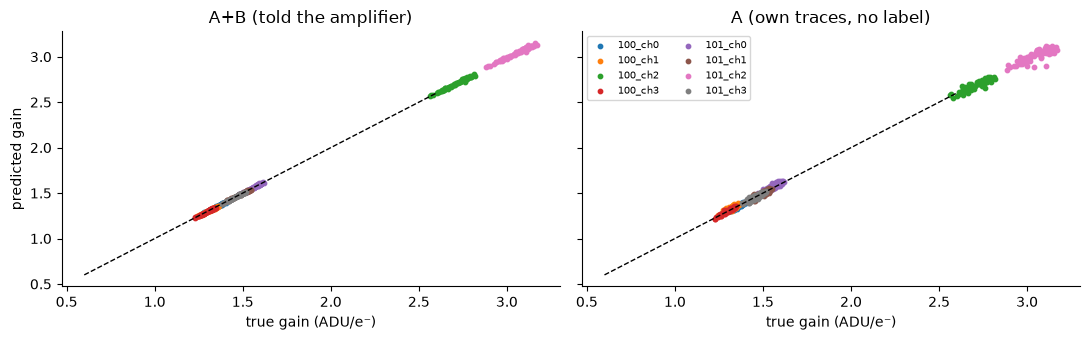

A+B (labels)                             sigma_e:   2.0 % (cover 0.84)   lambda:  11.0 % (cover 0.64)   gain:   0.4 % (cover 0.98)
A (no labels)                            sigma_e:   2.4 % (cover 0.78)   lambda:  11.0 % (cover 0.64)   gain:   1.3 % (cover 0.72)


In [3]:
te, cte = synthetic.make_dataset(60, seed=2, n_boards=2)
truth_t = np.log(te[TRUTH].to_numpy())
A = st.PhysicsStructured().fit(prep.transform(tr, ctr), Ytr)
mA, sA = A.predict(prep.transform(te, cte)); mAB, sAB = AB.predict(prep.transform(te, cte))
amp = (te.board.astype(str) + "_ch" + te.channel.astype(str)).to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a_, m_, title in ((ax[0], mAB, "A+B (told the amplifier)"), (ax[1], mA, "A (own traces, no label)")):
    for k, j in enumerate(np.unique(amp)):
        sel = amp == j; a_.scatter(np.exp(truth_t[sel, 2]), np.exp(m_[sel, 2]), s=10, label=j)
    a_.plot([0.6, 2.6], [0.6, 2.6], "k--", lw=1); a_.set_xlabel("true gain (ADU/e⁻)"); a_.set_title(title)
ax[0].set_ylabel("predicted gain"); ax[1].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()
_ = report("A+B (labels)", truth_t, mAB, sAB); _ = report("A (no labels)", truth_t, mA, sA)

## 3. Known amplifiers: how many packets?

Here there is one module. Three models are compared against the truth on a new scan:
* A+B;
* A without labels;
* A with the amplifier as a plain one-hot input (`kind="plain"`).

In [4]:
te1, cte1 = synthetic.make_dataset(60, seed=2); truth1 = np.log(te1[TRUTH].to_numpy())
rows = []
for n in (15, 30, 60):
    d, c = synthetic.make_dataset(n, seed=1); Yd = data.make_targets(d)[0]; p = st.StructuredPrep().fit(d)
    for label, kind in (("A+B (labels)", "hier"), ("A, one-hot label", "plain"), ("A, no labels", "none")):
        m, s = st.PhysicsStructured(kind).fit(p.transform(d, c), Yd).predict(p.transform(te1, cte1))
        e = 100 * np.sqrt(np.mean((m - truth1) ** 2, axis=0))
        rows.append({"packets": n, "model": label, "σe %": e[0], "λ %": e[1], "gain %": e[2],
                     "σe coverage": np.mean(np.abs(m[:, 0] - truth1[:, 0]) <= s[:, 0])})
display(pd.DataFrame(rows).set_index(["packets", "model"]).round(2))

σe %    λ %  gain %  σe coverage
packets model                                             
15      A+B (labels)      2.57  54.41    1.17         0.60
        A, one-hot label  2.91  54.34    1.14         0.54
        A, no labels      2.98  54.40    1.09         0.54
30      A+B (labels)      2.15  45.66    1.02         0.88
        A, one-hot label  3.26  45.73    1.94         0.71
        A, no labels      3.70  45.66    2.62         0.65
60      A+B (labels)      1.99   3.01    0.28         0.80
        A, one-hot label  2.16   3.04    0.89         0.74
        A, no labels      2.17   2.98    0.91         0.72

## 4. A new module: 0, 1, 2 and 5 of its packets

* **Training:** a scan of module 100 plus $k$ packets of module 101.
* **Testing:** new packets of module 101.

Besides the error, three scores are reported:
* **shape**: error after removing each amplifier's mean;
* **rank**: whether the settings are put in the right order, within each amplifier;
* **coverage** of the ±1σ error bars, i.e. whether the model *knows* when it is unsure.

In [5]:
def scores(df_, m, s):
    t = np.log(df_["truth.sigma_e"].to_numpy()); r = m[:, 0] - t
    a = (df_.board.astype(str) + df_.channel.astype(str)).to_numpy(); shape = r.copy()
    for j in np.unique(a): shape[a == j] -= r[a == j].mean()
    rank = np.mean([spearmanr(m[a == j, 0], t[a == j])[0] for j in np.unique(a)])
    return {"σe %": 100 * np.sqrt(np.mean(r ** 2)), "shape %": 100 * np.sqrt(np.mean(shape ** 2)), "rank": rank,
            "coverage": np.mean(np.abs(r) <= s[:, 0]), "mean σ predicted %": 100 * np.mean(s[:, 0])}

trn, ctrn = synthetic.make_dataset(80, seed=1, n_boards=2); tst, ctst = synthetic.make_dataset(40, seed=99, n_boards=2)
new = (tst.board == 101).to_numpy(); tst, ctst = tst[new].reset_index(drop=True), {k: v[new] for k, v in ctst.items()}
pk = trn.packet_id.str[4:].astype(int)
rows = []
for k in (0, 1, 2, 5):
    keep = ((trn.board == 100) | (pk < k)).to_numpy()
    d, c = trn[keep].reset_index(drop=True), {kk: v[keep] for kk, v in ctrn.items()}
    Yd = data.make_targets(d)[0]; p = st.StructuredPrep().fit(d)
    for label, kind in (("A+B (labels)", "hier"), ("A, no labels", "none")):
        m, s = st.PhysicsStructured(kind).fit(p.transform(d, c), Yd).predict(p.transform(tst, ctst))
        rows.append({"packets of the new module": k, "model": label, **scores(tst, m, s)})
res = pd.DataFrame(rows).set_index(["packets of the new module", "model"])
display(res.round(2))

σe %  shape %  rank  coverage  \
packets of the new module model                                          
0                         A+B (labels)  33.96     2.90  0.97      0.75   
                          A, no labels  26.73     2.61  0.97      0.71   
1                         A+B (labels)   4.06     3.06  0.97      0.54   
                          A, no labels   4.35     3.03  0.97      0.73   
2                         A+B (labels)   1.83     1.71  0.98      0.83   
                          A, no labels   3.33     2.68  0.98      0.83   
5                         A+B (labels)   1.85     1.74  0.98      0.83   
                          A, no labels   2.41     2.22  0.98      0.83   

                                        mean σ predicted %  
packets of the new module model                             
0                         A+B (labels)               31.44  
                          A, no labels                8.61  
1                         A+B (labels)                2.99  
                          A, no labels                4.67  
2                         A+B (labels)                2.64  
                          A, no labels                4.11  
5                         A+B (labels)                2.57  
                          A, no labels                3.13

The 0-packet error is large, but it is an average. Below, the same 0-packet models are broken down **amplifier by amplifier** of the new module.

In [6]:
keep = (trn.board == 100).to_numpy()
d, c = trn[keep].reset_index(drop=True), {kk: v[keep] for kk, v in ctrn.items()}
p = st.StructuredPrep().fit(d); Yd = data.make_targets(d)[0]; t = np.log(tst["truth.sigma_e"].to_numpy())
rows = []
for label, kind in (("A+B (labels)", "hier"), ("A, no labels", "none")):
    m, s = st.PhysicsStructured(kind).fit(p.transform(d, c), Yd).predict(p.transform(tst, ctst))
    for ch in range(4):
        sel = (tst.channel == ch).to_numpy(); r = m[sel, 0] - t[sel]
        rows.append({"model": label, "new amplifier": f"101_ch{ch}", "σe error %": 100 * np.sqrt(np.mean(r ** 2)),
                     "predicted σ %": 100 * np.mean(s[sel, 0]), "coverage": np.mean(np.abs(r) <= s[sel, 0])})
display(pd.DataFrame(rows).set_index(["model", "new amplifier"]).round(2))

σe error %  predicted σ %  coverage
model        new amplifier                                     
A+B (labels) 101_ch0              2.67          31.44      1.00
             101_ch1              5.20          31.43      1.00
             101_ch2             67.34          31.44      0.00
             101_ch3              6.63          31.43      1.00
A, no labels 101_ch0              3.19           8.37      1.00
             101_ch1              6.17           8.49      0.82
             101_ch2             52.89           9.52      0.00
             101_ch3              3.45           8.06      1.00

**Reading it:**
* **With 0 packets** of the new module, nothing can know a new amplifier's gain. Both models keep the shape and the order of the settings.
* **One amplifier causes most of the 0-packet error.** Three of the four new amplifiers are predicted within a few percent by *both* models: an
  amplifier's own traces already place it well. The fourth has an unusual gain, and both models miss it badly.
* **The error bars differ in kind:**
  * A+B knows the amplifiers are new, so it gives each of them the same wide error bar (the offset variance $c_a^2$). That is honest on
    average but too wide for the three typical amplifiers, and still too narrow for the odd one.
  * A has no notion of "new amplifier": narrow error bars, right for the typical amplifiers, and confidently wrong on the odd one.
* **After 1–2 packets** of the new module, both learn it. In this run A+B is ahead at 2 and 5 packets. Over 3 training scans in the project's
  test they were 2.0 % (A+B) and 2.2 % (A) after 2 packets.

## When to use it

| | A+B (labels) | A (no labels, default) |
|---|---|---|
| known amplifiers, few packets (≤ 30) | **better** (here σe 2.2 vs 3.7 %, gain 1.0 vs 2.6 % at 30) | worse |
| known amplifiers, 60 packets | equal for σe and λ; gain better | equal |
| a new module after 1–5 packets | equal or slightly better | equal or slightly worse |
| error bars for an amplifier never seen | wide for every new amplifier | narrow; confidently wrong on an unusual one |
| works for any amplifier without retraining its identity | no | **yes** |
| needs | the module and amplifier of every row | each amplifier's own traces |

* **A+B is worth it** when the set of amplifiers is fixed and known and packets are few. Its main gain is the **gain** itself: a per-amplifier
  constant that a label pins down directly (section 1).
* **A is the default** because it needs no labels, works for any amplifier, and catches up by ~60 packets.

The gap with few packets is the price of having no labels. Whether it exists on the real CCD, where the gains differ by only ~2 % on module 101,
is what level 1 will show.

In level 1, `physics_hier` runs A+B next to `physics` on the real packets, so the first real data will show which holds for the real CCD.

Next: **10 · Dark current and CIC, the joint fit.**